Référence land_cover : 1230 x 1920, CRS=EPSG:4326
Pixels Portugal : 1289658 / 2361600

Raster clippé sauvegardé : Data\soil\HWSD2_clipped.tif
Shape finale : 1920 x 1230 (identique au land_cover)


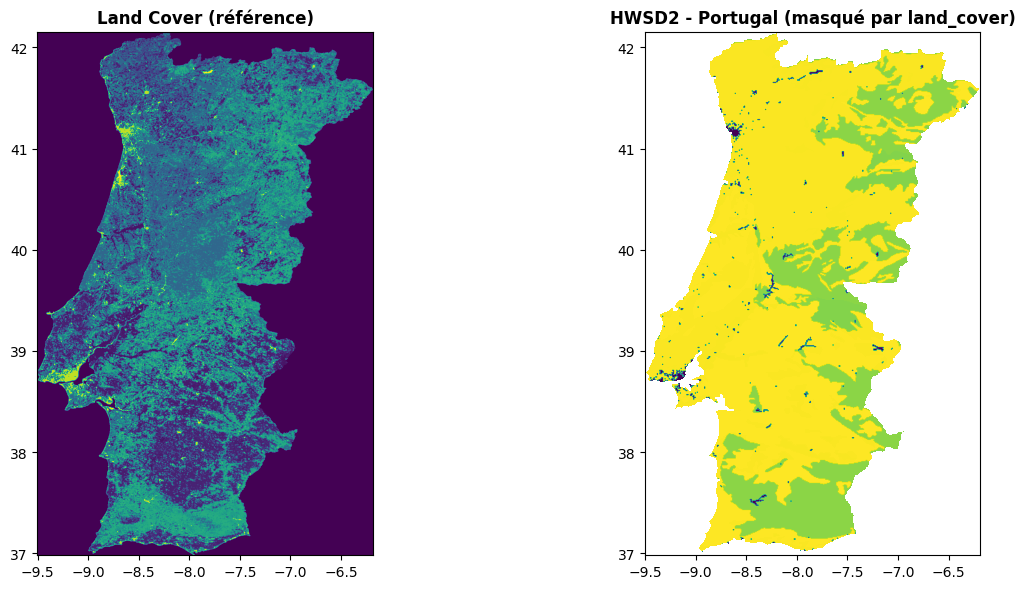

In [ ]:
import rasterio
from rasterio.warp import reproject, Resampling
import numpy as np
import matplotlib.pyplot as plt
from rasterio.plot import show


worldwide_path = r"Data\soil\HWSD2_RASTER\HWSD2.bil"
landcover_path = r"Data\Land_Cover\landcover_portugal_300m.tif"
output_path = r"Data\soil\HWSD2_clipped.tif"


with rasterio.open(landcover_path) as ref:
    ref_crs = ref.crs
    ref_transform = ref.transform
    ref_width = ref.width
    ref_height = ref.height
    lc_data = ref.read(1)
    lc_nodata = ref.nodata
    print(f"Référence land_cover : {ref_width} x {ref_height}, CRS={ref_crs}")


if lc_nodata is not None:
    portugal_mask = (lc_data != lc_nodata)
else:
    portugal_mask = (lc_data != 0)

print(f"Pixels Portugal : {portugal_mask.sum()} / {portugal_mask.size}")


with rasterio.open(worldwide_path) as src:
    dst_data = np.empty((1, ref_height, ref_width), dtype=src.dtypes[0])
    nodata_val = src.nodata if src.nodata is not None else 0

    reproject(
        source=rasterio.band(src, 1),
        destination=dst_data[0],
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=ref_transform,
        dst_crs=ref_crs,
        dst_nodata=nodata_val,
        resampling=Resampling.nearest
    )

    out_meta = src.meta.copy()
    out_meta.update({
        "driver": "GTiff",
        "crs": ref_crs,
        "transform": ref_transform,
        "width": ref_width,
        "height": ref_height,
        "count": 1,
        "nodata": nodata_val
    })


dst_data[0][~portugal_mask] = nodata_val


with rasterio.open(output_path, "w", **out_meta) as dest:
    dest.write(dst_data)

print(f"\nRaster clippé sauvegardé : {output_path}")
print(f"Shape finale : {ref_height} x {ref_width} (identique au land_cover)")


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

with rasterio.open(landcover_path) as lc:
    show(lc, ax=axes[0], title="Land Cover (référence)")

with rasterio.open(output_path) as clipped:
    show(clipped, ax=axes[1], title="HWSD2 - Portugal (masqué par land_cover)")

plt.tight_layout()
plt.show()